# Voice Digit Recognition: CNN (Speech Commands + FSDD)
**Pehle:** Runtime → Change runtime type → **T4 GPU**. Phir cells ko upar se neeche ek-ek karke Run karo.

## Cell 1: Data download (5-10 min)

In [1]:
!wget -q http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
!mkdir -p sc && tar -xzf speech_commands_v0.02.tar.gz -C sc
!git clone -q https://github.com/Jakobovski/free-spoken-digit-dataset.git
!pip -q install librosa
!ls sc | head -50

_background_noise_
backward
bed
bird
cat
dog
down
eight
five
follow
forward
four
go
happy
house
learn
left
LICENSE
marvin
nine
no
off
on
one
README.md
right
seven
sheila
six
stop
testing_list.txt
three
tree
two
up
validation_list.txt
visual
wow
yes
zero


## Cell 2: Speaker-independent split (validation_list / testing_list)

In [2]:
import os, time, numpy as np, librosa, tensorflow as tf
from tqdm import tqdm
from joblib import Parallel, delayed
root = "sc"
digits = ["zero","one","two","three","four","five","six","seven","eight","nine"]
label = {d:i for i,d in enumerate(digits)}
val  = set(open(f"{root}/validation_list.txt").read().split())
test = set(open(f"{root}/testing_list.txt").read().split())
train_files, val_files, test_files = [], [], []
for d in digits:
    for f in sorted(os.listdir(f"{root}/{d}")):
        p = f"{d}/{f}"
        (val_files if p in val else test_files if p in test else train_files).append(p)
print("train", len(train_files), "val", len(val_files), "test", len(test_files))

train 31158 val 3643 test 4107


## Cell 3: Audio → log-mel spectrogram (5-10 min)

In [3]:
def feat_from_signal(y, sr=16000):
    y = librosa.util.fix_length(y, size=sr)  # exactly 1 second
    m = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=400, hop_length=160, n_mels=40)
    return np.log(m + 1e-6).astype(np.float32)  # (40, 101)

def feat(path):
    y, _ = librosa.load(path, sr=16000)
    return feat_from_signal(y)

def build(files):
    X = Parallel(n_jobs=-1)(delayed(feat)(f"{root}/{p}") for p in tqdm(files))
    y = np.array([label[p.split("/")[0]] for p in files])
    return np.array(X), y

Xtr, ytr = build(train_files)
Xva, yva = build(val_files)
Xte, yte = build(test_files)
mu, sd = Xtr.mean(), Xtr.std()          # sirf train se
Xtr, Xva, Xte = [((x-mu)/sd)[..., None] for x in (Xtr, Xva, Xte)]   # (N,40,101,1)
print(Xtr.shape, Xva.shape, Xte.shape)

100%|██████████| 4107/4107 [00:06<00:00, 659.19it/s]


(31158, 40, 101, 1) (3643, 40, 101, 1) (4107, 40, 101, 1)


## Cell 4: Spectrogram ki tasveer (slide ke liye)

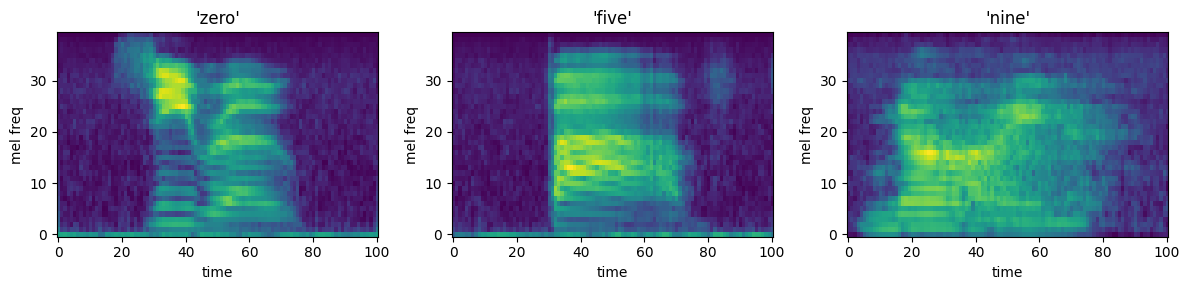

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(12,3))
for a, d in zip(ax, ["zero","five","nine"]):
    i = np.where(ytr == label[d])[0][0]
    a.imshow(Xtr[i,:,:,0], origin="lower", aspect="auto"); a.set_title(f"'{d}'")
    a.set_xlabel("time"); a.set_ylabel("mel freq")
plt.tight_layout(); plt.savefig("spectrograms.png", dpi=150); plt.show()

## Cell 5: CNN banao, 3 seeds par train karo

In [5]:
from tensorflow.keras import layers, models
def make_cnn():
    return models.Sequential([
        layers.Input((40,101,1)),
        layers.Conv2D(16,3,padding="same",activation="relu"), layers.BatchNormalization(), layers.MaxPool2D(),
        layers.Conv2D(32,3,padding="same",activation="relu"), layers.BatchNormalization(), layers.MaxPool2D(),
        layers.Conv2D(64,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(), layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")])

results, trained, histories = [], [], []
for seed in [0, 1, 2]:
    tf.keras.utils.set_random_seed(seed)
    m = make_cnn()
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    t = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=30, batch_size=64, verbose=2,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    tt = time.time() - t
    acc = m.evaluate(Xte, yte, verbose=0)[1]
    results.append((acc, tt)); trained.append(m); histories.append(h)
    print(f"seed {seed}: test acc {acc:.4f}, time {tt:.0f}s")
print("Parameters:", trained[0].count_params())

Epoch 1/30
487/487 - 28s - 58ms/step - accuracy: 0.6173 - loss: 1.3469 - val_accuracy: 0.6769 - val_loss: 1.2370
Epoch 2/30
487/487 - 3s - 7ms/step - accuracy: 0.8597 - loss: 0.5688 - val_accuracy: 0.8194 - val_loss: 0.7285
Epoch 3/30
487/487 - 4s - 8ms/step - accuracy: 0.9047 - loss: 0.3715 - val_accuracy: 0.8957 - val_loss: 0.4079
Epoch 4/30
487/487 - 3s - 7ms/step - accuracy: 0.9220 - loss: 0.2884 - val_accuracy: 0.9314 - val_loss: 0.2834
Epoch 5/30
487/487 - 3s - 7ms/step - accuracy: 0.9319 - loss: 0.2452 - val_accuracy: 0.9314 - val_loss: 0.2551
Epoch 6/30
487/487 - 4s - 7ms/step - accuracy: 0.9380 - loss: 0.2145 - val_accuracy: 0.9231 - val_loss: 0.2589
Epoch 7/30
487/487 - 5s - 10ms/step - accuracy: 0.9442 - loss: 0.1929 - val_accuracy: 0.9366 - val_loss: 0.2129
Epoch 8/30
487/487 - 3s - 7ms/step - accuracy: 0.9470 - loss: 0.1823 - val_accuracy: 0.9539 - val_loss: 0.1577
Epoch 9/30
487/487 - 3s - 7ms/step - accuracy: 0.9502 - loss: 0.1676 - val_accuracy: 0.9583 - val_loss: 0.152

## Cell 6: Training curve

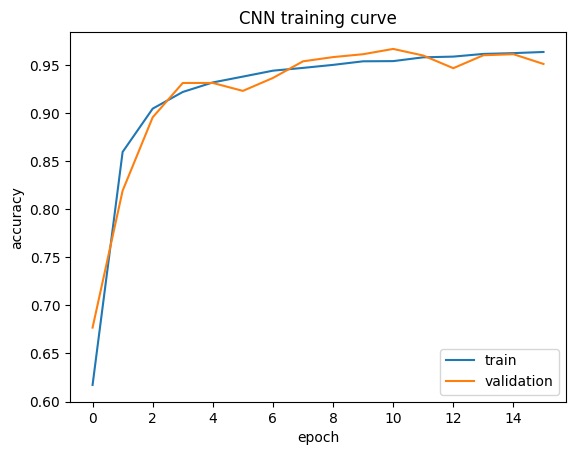

In [6]:
h = histories[0].history
plt.plot(h["accuracy"], label="train"); plt.plot(h["val_accuracy"], label="validation")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("CNN training curve")
plt.savefig("curve.png", dpi=150); plt.show()

## Cell 7: Confusion matrix (Speech Commands test)

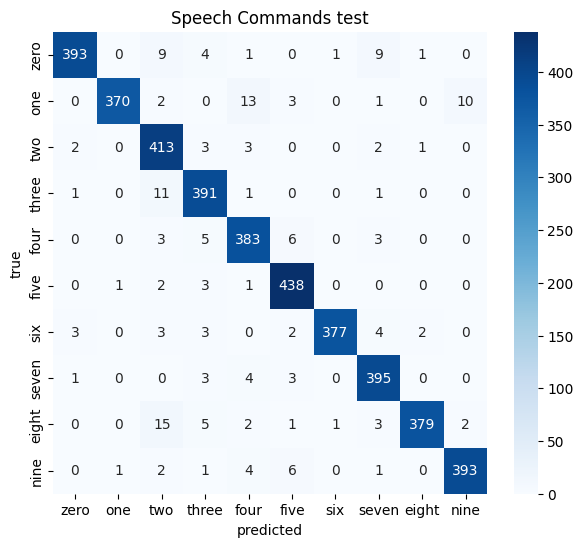

In [7]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
pred = trained[0].predict(Xte, verbose=0).argmax(1)
cm = confusion_matrix(yte, pred)
plt.figure(figsize=(7,6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=digits, yticklabels=digits)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Speech Commands test")
plt.savefig("cm_sc.png", dpi=150); plt.show()

## Cell 8: FSDD (8 kHz → 16 kHz resample) par evaluate

FSDD acc per seed: [0.8383, 0.879, 0.9143]


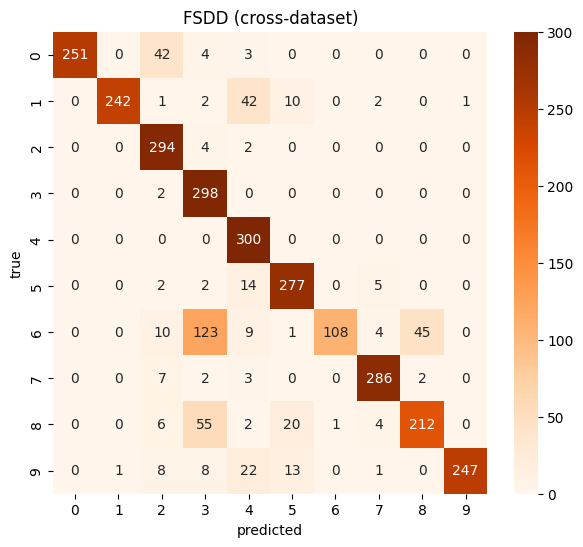

In [8]:
rec = "free-spoken-digit-dataset/recordings"
files = sorted(f for f in os.listdir(rec) if f.endswith(".wav"))
Xf, yf = [], []
for f in files:
    y, sr = librosa.load(f"{rec}/{f}", sr=None)                    # 8000 Hz
    y = librosa.resample(y, orig_sr=sr, target_sr=16000)           # 16000 Hz
    Xf.append(feat_from_signal(y)); yf.append(int(f.split("_")[0]))
Xf = ((np.array(Xf) - mu) / sd)[..., None]; yf = np.array(yf)      # train ka mu, sd
fs_accs = [m.evaluate(Xf, yf, verbose=0)[1] for m in trained]
print("FSDD acc per seed:", [round(a,4) for a in fs_accs])

pred = trained[0].predict(Xf, verbose=0).argmax(1)
plt.figure(figsize=(7,6)); sns.heatmap(confusion_matrix(yf, pred), annot=True, fmt="d", cmap="Oranges")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("FSDD (cross-dataset)")
plt.savefig("cm_fsdd.png", dpi=150); plt.show()

## Cell 9: Final result table (slide par lagao)

In [9]:
acc = np.array([r[0] for r in results])*100; tm = np.array([r[1] for r in results]); fs = np.array(fs_accs)*100
print("| Model | Params | Train time | Speech Commands test | FSDD |")
print("|---|---|---|---|---|")
print(f"| CNN | {trained[0].count_params():,} | {tm.mean():.0f}s | {acc.mean():.1f}% ± {acc.std():.1f} | {fs.mean():.1f}% ± {fs.std():.1f} |")

| Model | Params | Train time | Speech Commands test | FSDD |
|---|---|---|---|---|
| CNN | 24,394 | 84s | 95.7% ± 0.1 | 87.7% ± 3.1 |


In [55]:
from IPython.display import Javascript, display
from google.colab import output
from base64 import b64decode

JS = """
const sleep = t => new Promise(r => setTimeout(r, t));
const b2text = b => new Promise(r => {const f = new FileReader(); f.onloadend = e => r(e.srcElement.result); f.readAsDataURL(b)});
var record = t => new Promise(async res => {
  const stream = await navigator.mediaDevices.getUserMedia({audio:true});
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.onstop = async () => res(await b2text(new Blob(chunks)));
  rec.start(); await sleep(t); rec.stop();
});
"""

def predict_voice(sec=2000):
    display(Javascript(JS))
    print("🎤 Ab bolo...")
    data = output.eval_js(f"record({sec})")
    open("rec.webm", "wb").write(b64decode(data.split(",")[1]))
    !ffmpeg -y -i rec.webm -ar 16000 -ac 1 rec.wav -loglevel quiet
    y, _ = librosa.load("rec.wav", sr=16000)
    # sabse tez 1 second wala hissa lo (jahan tum bolti ho)
    if len(y) > 16000:
        e = np.convolve(y**2, np.ones(16000), mode="valid")
        s = int(e.argmax()); y = y[s:s+16000]
    x = ((feat_from_signal(y) - mu) / sd)[None, ..., None]
    p = trained[0].predict(x, verbose=0)[0]
    top = p.argsort()[::-1][:3]
    print(f"\n👉 Digit: {top[0]}  (confidence {p[top[0]]:.0%})")
    print("Top 3:", [(int(i), f"{p[i]:.0%}") for i in top])

predict_voice()

<IPython.core.display.Javascript object>

🎤 Ab bolo...

👉 Digit: 5  (confidence 98%)
Top 3: [(5, '98%'), (9, '1%'), (3, '1%')]


## Cell 10: Demo (apni audio upload karke digit pata karo)

In [11]:
from google.colab import files as colab_files
up = colab_files.upload()
for name in up:
    y, _ = librosa.load(name, sr=16000)
    x = ((feat_from_signal(y) - mu) / sd)[None, ..., None]
    p = trained[0].predict(x, verbose=0)[0]
    print(name, "→ digit:", p.argmax(), f"(confidence {p.max():.0%})")